# 05 — Training EfficientNet-B0

Studio Proyek 2 · Klasifikasi 5 jenis sampah (IF25-40401)

Percobaan **model kedua**: mengganti backbone dari ResNet-18 ke **EfficientNet-B0 pretrained ImageNet** (torchvision). Tujuannya membandingkan apakah backbone yang lebih efisien memberi Macro-F1 lebih baik pada split validasi lokal.

Notebook ini menghasilkan berkas submission dengan kontrak yang sama:

- `submission/model.py` — `get_model()` (arsitektur saja) dan `get_transform()`
- `submission/model.pth` — `state_dict` model terbaik

Dijalankan di Google Colab dengan runtime GPU (T4). Notebook 04 (baseline ResNet-18) tetap disimpan sebagai pembanding.


## 1. Setup, import, dan ambil kode repo

Seluruh `import` dikumpulkan di sini agar sel berikutnya bersih. Sel ini juga mengecek runtime, memasang `gdown`, meng-clone repo, dan memuat metrik resmi dari `evaluate.py`.

In [1]:
import os, sys, subprocess, shutil, random, time
from pathlib import Path

IN_COLAB = "google.colab" in sys.modules

try:
    import torch, torchvision
except ImportError:
    subprocess.run([sys.executable, "-m", "pip", "-q", "install", "torch", "torchvision"], check=True)
    import torch, torchvision

import numpy as np
import torch.nn as nn
from torch.utils.data import DataLoader
from torchvision import datasets, models
from PIL import Image
import matplotlib.pyplot as plt

print("Python      :", sys.version.split()[0])
print("Colab       :", IN_COLAB)
print("torch       :", torch.__version__)
print("torchvision :", torchvision.__version__)
if torch.cuda.is_available():
    print("GPU         :", torch.cuda.get_device_name(0))
else:
    print("GPU         : tidak ada -> aktifkan Runtime > Change runtime type > T4 GPU")

if IN_COLAB:
    subprocess.run([sys.executable, "-m", "pip", "-q", "install", "gdown"], check=False)
    from google.colab import files as colab_files

# Clone repo (Colab) atau pakai folder lokal tempat notebook ini berada.
REPO_URL = "https://github.com/Escavora/studio-proyek2-cnn-klasifikasi-sampah.git"
if IN_COLAB:
    REPO_DIR = Path("/content/studio-proyek2-cnn-klasifikasi-sampah")
    if not REPO_DIR.exists():
        os.system(f"git clone {REPO_URL} {REPO_DIR}")
    else:
        os.system(f"git -C {REPO_DIR} pull --ff-only")
else:
    REPO_DIR = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()

os.chdir(REPO_DIR)
if str(REPO_DIR) not in sys.path:
    sys.path.insert(0, str(REPO_DIR))
print("repo        :", REPO_DIR)

from evaluate import metrics
from preprocessing import (  # tahap preprocessing bersama dengan notebook 03
    SEED, find_duplicate_groups, get_train_transform, get_val_transform, split_by_group, write_split,
)
print("metrik resmi dari evaluate.py dan tahap preprocessing dimuat.")

Python      : 3.13.15
Colab       : True
torch       : 2.11.0+cu130
torchvision : 0.26.0+cu130
GPU         : Tesla T4
repo        : /content/studio-proyek2-cnn-klasifikasi-sampah
metrik resmi dari evaluate.py dimuat.


## 2. Dataset

Dataset berasal dari folder Google Drive yang dibagikan, strukturnya `my_train/<kelas>/` + `my_val/<kelas>/` (sudah ter-split).

Supaya mount berhasil: buka tautan folder dataset di Drive, klik kanan foldernya → **Add shortcut to Drive** → pilih **My Drive**. Setelah itu dataset muncul di bawah `/content/drive/MyDrive`.

**Penting:** setelah ketemu, dataset disalin sekali ke disk lokal Colab (`/content/dataset_local`). Membaca gambar langsung dari mount Drive sangat lambat (ribuan file diakses lewat jaringan), sehingga verifikasi & training bisa tertahan lama. Salinan lokal membuat semuanya jauh lebih cepat.

Bila dataset sudah ada di lain tempat, isi `MANUAL_DIR` di bawah.


In [3]:
DRIVE_FOLDER_ID = "1IRx6eGOaJt661-Yq9YVntQeJ6ZTaoNGo"

# Bila dataset sudah tersedia lokal/Drive, isi folder induknya (berisi my_train/+my_val/
# atau train/). Contoh: "/content/drive/MyDrive/studio2/dataset"
MANUAL_DIR = None

CLASSES = ["botol_plastik", "gelas_plastik", "kertas_kardus", "saset_kemasan", "styrofoam"]
IMG_EXTS = {".jpg", ".jpeg", ".png", ".webp", ".bmp"}


def has_classes(d):
    d = Path(d)
    return d.is_dir() and all((d / c).is_dir() for c in CLASSES)


def find_dataset_root(start):
    # Kembalikan (folder induk dataset, jenis) atau (None, None).
    # Wajib punya KELIMA kelas, supaya folder hasil unduhan setengah jalan tidak dianggap valid.
    start = Path(start)
    if not start.exists():
        return None, None
    cands = [start] + sorted(p for p in start.rglob("*") if p.is_dir())
    for d in cands:
        if has_classes(d / "my_train") and has_classes(d / "my_val"):
            return d, "split"
    for d in cands:
        if has_classes(d / "train"):
            return d, "raw"
    return None, None


def mount_drive_and_find():
    from google.colab import drive
    if not Path("/content/drive/MyDrive").exists():
        drive.mount("/content/drive")
    return find_dataset_root("/content/drive/MyDrive")


def gdown_folder(dest):
    # Cadangan. Bisa gagal dengan FolderContentsMaximumLimitError pada folder besar.
    dest = Path(dest)
    dest.mkdir(parents=True, exist_ok=True)
    os.system(f"gdown --folder {DRIVE_FOLDER_ID} -O {dest} --retries 3 --continue")
    return find_dataset_root(dest)


ROOT, kind = None, None

if MANUAL_DIR and Path(MANUAL_DIR).exists():
    ROOT, kind = find_dataset_root(MANUAL_DIR)
elif has_classes(REPO_DIR / "train") or (has_classes(REPO_DIR / "my_train") and has_classes(REPO_DIR / "my_val")):
    ROOT, kind = find_dataset_root(REPO_DIR)

if ROOT is None and IN_COLAB:
    # 1) prioritaskan mount Drive (andal untuk folder besar)
    try:
        ROOT, kind = mount_drive_and_find()
        if ROOT is not None:
            print("dataset ditemukan lewat mount Google Drive.")
    except Exception as e:
        print("mount Drive tidak tersedia/tidak authorized:", e)

# 2) cadangan: gdown
if ROOT is None and IN_COLAB:
    print("mencoba mengunduh via gdown (bisa gagal untuk folder > 50 file/folder) ...")
    ROOT, kind = gdown_folder("/content/dataset")

assert ROOT is not None, (
    "Dataset tidak ditemukan.\n"
    "  - Mount Drive lalu 'Add shortcut to Drive' folder dataset ke My Drive, atau\n"
    "  - isi MANUAL_DIR dengan path folder dataset, atau\n"
    "  - unduh manual dari Google Drive lalu taruh di root repo (train/ atau my_train/+my_val/)."
)

# Salin dataset ke disk lokal Colab sekali saja. Membaca ribuan gambar langsung dari
# mount Google Drive sangat lambat (per-file lewat jaringan), sehingga verifikasi dan
# training bisa tertahan. Setelah disalin ke /content, semua operasi jadi cepat.
LOCAL_ROOT = Path("/content/dataset_local")
if IN_COLAB and "/content/drive" in str(ROOT) and not LOCAL_ROOT.exists():
    print(f"menyalin dataset ke disk lokal ({LOCAL_ROOT}) ...")
    t_copy = time.time()
    shutil.copytree(ROOT, LOCAL_ROOT)
    print(f"selesai menyalin dalam {time.time() - t_copy:.0f} detik.")
if LOCAL_ROOT.exists() and find_dataset_root(LOCAL_ROOT)[0] is not None:
    ROOT, kind = find_dataset_root(LOCAL_ROOT)
    print("memakai salinan lokal:", ROOT)

if kind == "split":
    TRAIN_DIR, VAL_DIR = ROOT / "my_train", ROOT / "my_val"
    SRC_DIR = TRAIN_DIR
    print("struktur  : sudah ter-split (my_train/ + my_val/)")
    print("train dir :", TRAIN_DIR)
    print("val dir   :", VAL_DIR)
else:
    DATA_DIR = ROOT / "train"
    TRAIN_DIR = VAL_DIR = None
    SRC_DIR = DATA_DIR
    print("struktur  : train/ mentah, akan di-split otomatis di langkah 4")
    print("DATA_DIR  :", DATA_DIR)

Mounted at /content/drive
dataset ditemukan lewat mount Google Drive.
menyalin dataset ke disk lokal (/content/dataset_local) ...
selesai menyalin dalam 305 detik.
memakai salinan lokal: /content/dataset_local
struktur  : sudah ter-split (my_train/ + my_val/)
train dir : /content/dataset_local/my_train
val dir   : /content/dataset_local/my_val


## 3. Verifikasi dataset

Cek jumlah gambar per kelas dan pastikan setiap berkas bisa dibuka, supaya training tidak gagal di tengah jalan.

In [4]:
files_by_class = {}
for c in CLASSES:
    files_by_class[c] = sorted(p for p in (SRC_DIR / c).iterdir() if p.suffix.lower() in IMG_EXTS)

total = sum(len(fs) for fs in files_by_class.values())
for c, fs in files_by_class.items():
    print(f"{c:<15} {len(fs):>5}")
print(f"{'TOTAL':<15} {total:>5}")

found = sorted(p.name for p in SRC_DIR.iterdir() if p.is_dir())
assert found == CLASSES, f"folder kelas tidak sesuai: {found}"

corrupt = []
for fs in files_by_class.values():
    for p in fs:
        try:
            with Image.open(p) as im:
                im.verify()
        except Exception as e:
            corrupt.append((p, repr(e)))
assert not corrupt, f"ada gambar rusak: {corrupt[:3]}"
print("semua gambar valid.")

botol_plastik     445
gelas_plastik     443
kertas_kardus     311
saset_kemasan     573
styrofoam         571
TOTAL            2343
semua gambar valid.


## 4. Split validasi lokal

Kalau di langkah 2 dataset sudah punya `my_train/` + `my_val/`, langkah ini dilewati (dipakai langsung).

Kalau dataset masih `train/` mentah, 15% dipotong sebagai validasi lokal. Karena EDA menemukan pasangan near-duplicate, split dilakukan **per grup duplikat** (dHash 256-bit), bukan per gambar, agar tidak ada gambar yang sama muncul di train dan val sekaligus.

Split tidak ditulis ulang di sini: notebook ini memanggil fungsi yang sama dengan `03_preprocessing.ipynb` (`find_duplicate_groups()`, `split_by_group()`, `write_split()` di `preprocessing.py`), jadi hasil split-nya identik.

In [5]:
if TRAIN_DIR is not None:
    print("dataset sudah ter-split -> memakai my_train/ dan my_val/ dari dataset")
else:
    TRAIN_DIR, VAL_DIR = REPO_DIR / "my_train", REPO_DIR / "my_val"
    all_files, labels = [], []
    for c in CLASSES:
        fs = sorted(p for p in (DATA_DIR / c).iterdir() if p.suffix.lower() in IMG_EXTS)
        all_files += fs
        labels += [c] * len(fs)
    labels = np.array(labels)
    print("total gambar:", len(all_files))

    if TRAIN_DIR.is_dir() and VAL_DIR.is_dir():
        print("split sudah ada -> dilewati")
    else:
        # Sama dengan 03_preprocessing.ipynb: split stratified per grup near-duplicate
        group_id, pairs = find_duplicate_groups(all_files)
        print("pasangan near-duplicate:", len(pairs))
        write_split(all_files, labels, split_by_group(labels, group_id), TRAIN_DIR, VAL_DIR)
        print("split dibuat.")

for c in CLASSES:
    assert (TRAIN_DIR / c).is_dir() and (VAL_DIR / c).is_dir(), f"kelas {c} tidak lengkap"
    n_tr = len(list((TRAIN_DIR / c).iterdir()))
    n_va = len(list((VAL_DIR / c).iterdir()))
    print(f"{c:<15} train={n_tr:>5}  val={n_va:>4}")
print("TRAIN_DIR:", TRAIN_DIR)
print("VAL_DIR  :", VAL_DIR)

dataset sudah ter-split -> memakai my_train/ dan my_val/ dari dataset
botol_plastik   train=  445  val=  78
gelas_plastik   train=  443  val=  78
kertas_kardus   train=  311  val=  54
saset_kemasan   train=  573  val= 100
styrofoam       train=  571  val= 100
TRAIN_DIR: /content/dataset_local/my_train
VAL_DIR  : /content/dataset_local/my_val


## 5. Transform (dari tahap preprocessing)

Transform **tidak didefinisikan ulang** di sini. Augmentasi sudah ditetapkan di tahap `03_preprocessing.ipynb` dan ditulis di `preprocessing.py` (root repo), jadi notebook ini cukup meng-import-nya:

- Train: `get_train_transform()` → `RandomResizedCrop(224, scale 0,5–1,0)`, flip horizontal, `ColorJitter`, normalisasi ImageNet.
- Validasi: `get_val_transform()` → `get_transform()` dari `submission/model.py` (`Resize(256)` + `CenterCrop(224)`), kontrak `evaluate.py`.

Augmentasi tidak disimpan ke disk; `my_train/` tetap berisi gambar asli. `DataLoader` menerapkannya *on-the-fly* setiap kali gambar diambil, sehingga tiap epoch model melihat variasi acak yang berbeda. Karena itu transform tetap dipasang ke `ImageFolder` di langkah 7.

Transform yang sama dipakai notebook 04, jadi perbandingan ResNet-18 vs EfficientNet-B0 adil. EfficientNet-B0 memakai ukuran input dan normalisasi ImageNet yang sama (224 px, mean/std standar), jadi transform tidak perlu diubah.

In [ ]:
NUM_CLASSES = 5

train_tf = get_train_transform()
val_tf = get_val_transform()
print("train_tf:", train_tf)
print("val_tf  :", val_tf)

## 6. Model

`build_model()` membangun **EfficientNet-B0 pretrained ImageNet** dengan head 5 kelas. Bobot pretrained dipakai saat training; `get_model()` di `submission/model.py` nanti hanya membangun arsitektur tanpa mengunduh bobot.

EfficientNet-B0 jauh lebih hemat parameter (±5,3 juta vs 11,2 juta milik ResNet-18) namun ImageNet top-1 lebih tinggi (77,7% vs 69,8%). Dropout classifier dinaikkan (0,2 → 0,3) sebagai pengendali overfitting pada dataset yang relatif kecil.


In [7]:
def build_model(pretrained=True):
    weights = models.EfficientNet_B0_Weights.IMAGENET1K_V1 if pretrained else None
    model = models.efficientnet_b0(weights=weights)
    # Ganti head classifier: Dropout lalu Linear 1280 -> 5 kelas.
    model.classifier[0] = nn.Dropout(p=0.3, inplace=True)
    model.classifier[1] = nn.Linear(model.classifier[1].in_features, NUM_CLASSES)
    return model


_model = build_model()
print("parameter total :", sum(p.numel() for p in _model.parameters()))
print("head            :", _model.classifier[1])
del _model


Downloading: "https://download.pytorch.org/models/efficientnet_b0_rwightman-7f5810bc.pth" to /root/.cache/torch/hub/checkpoints/efficientnet_b0_rwightman-7f5810bc.pth


100%|██████████| 20.5M/20.5M [00:00<00:00, 145MB/s]


parameter total : 4013953
head            : Linear(in_features=1280, out_features=5, bias=True)


## 7. DataLoader

`ImageFolder` memberi label dari nama folder (urut alfabetis, sama dengan kontrak submission). Train diacak, val tidak.

In [8]:
device = "cuda" if torch.cuda.is_available() else "cpu"
print("device:", device)

train_ds = datasets.ImageFolder(TRAIN_DIR, transform=train_tf)
val_ds = datasets.ImageFolder(VAL_DIR, transform=val_tf)
assert train_ds.classes == CLASSES == val_ds.classes, (train_ds.classes, CLASSES)

num_workers = 2 if IN_COLAB else 0
train_dl = DataLoader(train_ds, batch_size=32, shuffle=True,
                      num_workers=num_workers, pin_memory=(device == "cuda"))
val_dl = DataLoader(val_ds, batch_size=32, shuffle=False,
                    num_workers=num_workers, pin_memory=(device == "cuda"))

print("class_to_idx:", train_ds.class_to_idx)
print(f"train: {len(train_ds)} gambar | val: {len(val_ds)} gambar")

device: cuda
class_to_idx: {'botol_plastik': 0, 'gelas_plastik': 1, 'kertas_kardus': 2, 'saset_kemasan': 3, 'styrofoam': 4}
train: 2343 gambar | val: 410 gambar


## 8. Training

Konfigurasi mengikuti pola notebook 04 (AdamW + CosineAnnealingLR + label smoothing), dengan dua penyesuaian khusus EfficientNet-B0:

- **epoch dinaikkan 8 → 15**, karena backbone lebih kecil biasanya baru konvergen setelah belasan epoch;
- **learning rate 5e-4** (sedikit di atas baseline) agar fitur pretrained bergerak cukup, sementara `label_smoothing=0.1`, dropout 0,3, augmentasi, dan `weight_decay` menahan overfitting.

Checkpoint terbaik tetap dipilih berdasarkan **Macro-F1 validasi**, bukan akurasi.


In [9]:
EPOCHS = 15
LR = 5e-4
WEIGHT_DECAY = 1e-4
LABEL_SMOOTHING = 0.1

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)


def evaluate_model(model, loader):
    model.eval()
    ys, ps = [], []
    with torch.no_grad():
        for x, y in loader:
            x = x.to(device)
            ps += model(x).argmax(1).cpu().tolist()
            ys += y.tolist()
    return metrics(ys, ps)


model = build_model(pretrained=True).to(device)
opt = torch.optim.AdamW(model.parameters(), lr=LR, weight_decay=WEIGHT_DECAY)
sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=EPOCHS)
loss_fn = nn.CrossEntropyLoss(label_smoothing=LABEL_SMOOTHING)

best_f1, best_state, history = -1.0, None, []
for ep in range(1, EPOCHS + 1):
    model.train()
    t0, running = time.time(), 0.0
    for x, y in train_dl:
        x, y = x.to(device), y.to(device)
        opt.zero_grad()
        loss = loss_fn(model(x), y)
        loss.backward()
        opt.step()
        running += loss.item() * len(y)
    sched.step()

    m = evaluate_model(model, val_dl)
    history.append({"epoch": ep, "loss": running / len(train_ds),
                    "macro_f1": m["macro_f1"], "accuracy": m["accuracy"]})
    flag = ""
    if m["macro_f1"] > best_f1:
        best_f1 = m["macro_f1"]
        best_state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}
        flag = "  <- disimpan"
    print(f"epoch {ep:2d}/{EPOCHS}  loss={running / len(train_ds):.4f}  "
          f"val_macroF1={m['macro_f1']:.4f}  val_acc={m['accuracy']:.4f}  "
          f"({time.time() - t0:.0f}s){flag}")

model.load_state_dict(best_state)
(REPO_DIR / "submission").mkdir(exist_ok=True)
torch.save(model.state_dict(), REPO_DIR / "submission" / "model.pth")
print(f"\nMacro-F1 validasi terbaik: {best_f1:.4f}")
print("disimpan ke submission/model.pth")

epoch  1/15  loss=0.8452  val_macroF1=0.9161  val_acc=0.9195  (33s)  <- disimpan
epoch  2/15  loss=0.5936  val_macroF1=0.9132  val_acc=0.9146  (31s)
epoch  3/15  loss=0.5059  val_macroF1=0.9312  val_acc=0.9317  (31s)  <- disimpan
epoch  4/15  loss=0.4943  val_macroF1=0.9381  val_acc=0.9415  (31s)  <- disimpan
epoch  5/15  loss=0.4700  val_macroF1=0.9362  val_acc=0.9366  (30s)
epoch  6/15  loss=0.4581  val_macroF1=0.9405  val_acc=0.9415  (30s)  <- disimpan
epoch  7/15  loss=0.4487  val_macroF1=0.9393  val_acc=0.9439  (30s)
epoch  8/15  loss=0.4380  val_macroF1=0.9487  val_acc=0.9512  (31s)  <- disimpan
epoch  9/15  loss=0.4407  val_macroF1=0.9375  val_acc=0.9390  (30s)
epoch 10/15  loss=0.4310  val_macroF1=0.9472  val_acc=0.9488  (31s)
epoch 11/15  loss=0.4281  val_macroF1=0.9581  val_acc=0.9585  (31s)  <- disimpan
epoch 12/15  loss=0.4211  val_macroF1=0.9532  val_acc=0.9537  (31s)
epoch 13/15  loss=0.4214  val_macroF1=0.9522  val_acc=0.9537  (31s)
epoch 14/15  loss=0.4176  val_macroF1=

## 9. Kurva training

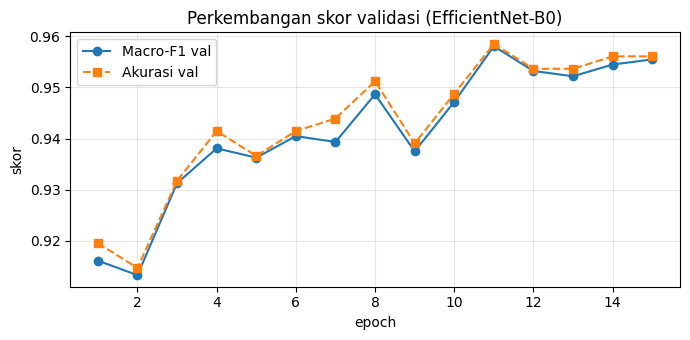

In [10]:
ep = [h["epoch"] for h in history]
fig, ax = plt.subplots(figsize=(7, 3.5))
ax.plot(ep, [h["macro_f1"] for h in history], "o-", label="Macro-F1 val")
ax.plot(ep, [h["accuracy"] for h in history], "s--", label="Akurasi val")
ax.set_xlabel("epoch")
ax.set_ylabel("skor")
ax.set_title("Perkembangan skor validasi (EfficientNet-B0)")
ax.legend()
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()


## 10. Evaluasi model terbaik

Hitung Macro-F1, akurasi, F1 per kelas, dan confusion matrix pada `my_val/`, lalu bandingkan dengan hasil baseline ResNet-18 (**0,9229**) untuk mengisi tabel Hasil di `README.md`.


Macro-F1 : 0.9581
Akurasi  : 0.9585
  F1 botol_plastik   0.9548
  F1 gelas_plastik   0.9625
  F1 kertas_kardus   0.9533
  F1 saset_kemasan   0.9641
  F1 styrofoam       0.9557


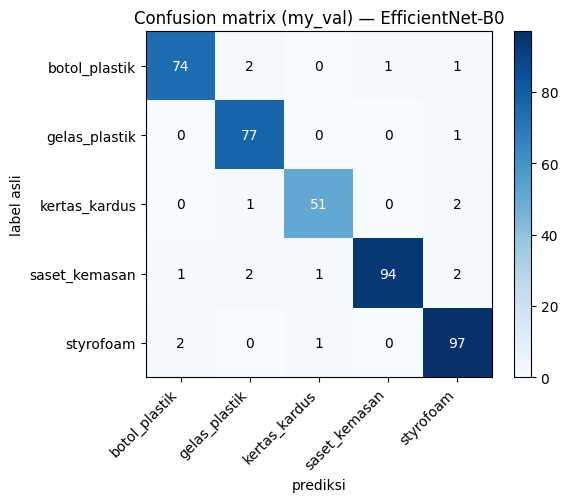


Macro-F1 lokal (my_val) = 0.9581 -> bandingkan dengan baseline ResNet-18 (0,9229).


In [11]:
m = evaluate_model(model, val_dl)
print(f"Macro-F1 : {m['macro_f1']:.4f}")
print(f"Akurasi  : {m['accuracy']:.4f}")
for c, f in m["per_class_f1"].items():
    print(f"  F1 {c:<15} {f:.4f}")

cm = np.array(m["confusion_matrix"])
fig, ax = plt.subplots(figsize=(6, 5))
im = ax.imshow(cm, cmap="Blues")
ax.set_xticks(range(len(CLASSES)), CLASSES, rotation=45, ha="right")
ax.set_yticks(range(len(CLASSES)), CLASSES)
for i in range(len(CLASSES)):
    for j in range(len(CLASSES)):
        ax.text(j, i, cm[i, j], ha="center", va="center",
                color="white" if cm[i, j] > cm.max() / 2 else "black")
ax.set_xlabel("prediksi")
ax.set_ylabel("label asli")
ax.set_title("Confusion matrix (my_val) \u2014 EfficientNet-B0")
fig.colorbar(im)
plt.tight_layout()
plt.show()

print(f"\nMacro-F1 lokal (my_val) = {m['macro_f1']:.4f} "
      "-> bandingkan dengan baseline ResNet-18 (0,9229).")


## 11. Tulis berkas submission

Tulis `submission/model.py` dan `submission/requirements.txt` sesuai kontrak, lalu cek ukuran `model.pth`.

Perhatikan: menjalankan notebook ini **menimpa** `submission/model.pth` dan `submission/model.py` dengan versi EfficientNet-B0. Simpan dulu `model.pth` baseline ResNet-18 di laptop sebelum mengganti, agar bisa dibandingkan dan dipilih yang terbaik.


In [12]:
model_py = """
# Submission Studio 2 - EfficientNet-B0 pretrained ImageNet.

import torch.nn as nn
from torchvision import models, transforms

NUM_CLASSES = 5


def get_model():
    # Arsitektur saja: tanpa mengunduh bobot (evaluate.py yang memuat model.pth).
    model = models.efficientnet_b0(weights=None)
    model.classifier[0] = nn.Dropout(p=0.3, inplace=True)
    model.classifier[1] = nn.Linear(model.classifier[1].in_features, NUM_CLASSES)
    return model


def get_transform():
    # Harus sama dengan transform validasi saat training.
    return transforms.Compose([
        transforms.Resize(256),
        transforms.CenterCrop(224),
        transforms.ToTensor(),
        transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225]),
    ])
"""

sub = REPO_DIR / "submission"
sub.mkdir(exist_ok=True)
(sub / "model.py").write_text(model_py, encoding="utf-8")
(sub / "requirements.txt").write_text(
    "# paket tambahan di luar environment standar (kosong: EfficientNet-B0 dari torchvision)\n",
    encoding="utf-8")

size_mb = (sub / "model.pth").stat().st_size / 1e6
print("model.py & requirements.txt ditulis.")
print(f"ukuran model.pth: {size_mb:.1f} MB (batas tugas 500 MB, batas GitHub 100 MB)")


model.py & requirements.txt ditulis.
ukuran model.pth: 16.3 MB (batas tugas 500 MB, batas GitHub 100 MB)


## 12. Uji dengan `evaluate.py`

Jalankan skrip evaluasi resmi dengan submission EfficientNet-B0 untuk memastikan kontraknya lolos.


In [13]:
hasil = subprocess.run(
    [sys.executable, "evaluate.py", "--submission", "./submission", "--data", str(VAL_DIR)],
    capture_output=True, text=True,
)
print(hasil.stdout)
if hasil.returncode != 0:
    print(hasil.stderr)

device=cuda  gambar=410

Macro-F1 : 0.9581
Akurasi  : 0.9585
  F1 botol_plastik   0.9548
  F1 gelas_plastik   0.9625
  F1 kertas_kardus   0.9533
  F1 saset_kemasan   0.9641
  F1 styrofoam       0.9557
Confusion matrix (baris = label asli, kolom = prediksi):
  botol_plastik   [74, 2, 0, 1, 1]
  gelas_plastik   [0, 77, 0, 0, 1]
  kertas_kardus   [0, 1, 51, 0, 2]
  saset_kemasan   [1, 2, 1, 94, 2]
  styrofoam       [2, 0, 1, 0, 97]

